# 07 — Ekstraksi Fitur sMRI FreeSurfer untuk Seluruh Subjek

> [!IMPORTANT]
> **Konteks Alur Penelitian: Ekstraksi sMRI FreeSurfer 5.1 ABIDE I**
> Notebook ini adalah bagian dari alur studi pendahuluan khusus **ABIDE I (PCP/C-PAC & FreeSurfer 5.1)** dengan kohort awal N = 1.097.
> Untuk penelitian gabungan multi-situs utama (**ABIDE I + ABIDE II**) yang menggunakan pipeline seragam **DCAN (ABCD-HCP)** dengan total kohort final **N = 1.638 subjek**, silakan merujuk langsung ke **Notebook 09 (09_kohort_dcan_abide1_abide2.ipynb)**. Ekstraksi sMRI untuk kohort gabungan DCAN (Skenario S2–S4) dilakukan secara terstandarisasi di Notebook 12 & 13.


Untuk **seluruh subjek ABIDE I**, notebook ini memakai hasil **FreeSurfer 5.1** yang sudah dijalankan PCP. Notebook ini mengambil berkas statistik FreeSurfer, mengubahnya menjadi **satu tabel fitur**, lalu melakukan **validasi dan QC**.

| Bagian | Isi | Keluaran |
| :---: | :--- | :--- |
| 1 | Ketersediaan & pengunduhan berkas statistik | `data/processed/freesurfer_stats/<FILE_ID>/` |
| 2 | Pemeriksaan identitas berkas | — |
| 3 | Parsing menjadi tabel fitur | `smri_freesurfer_fitur.csv` |
| 4 | Kamus fitur | `result/tabel/07b_kamus_fitur_smri.csv` |
| 5 | Uji kewajaran biologis | — |
| 6 | QC hasil FreeSurfer | `result/tabel/07b_qc_freesurfer.csv` |
| 7 | Gambaran ASD vs kontrol & efek situs (deskriptif) | — |

Cakupan: **subjek rilis PCP** (`FILE_ID` ≠ `no_filename`), sesuai keputusan kohort.

> **Peran dalam alur akhir penelitian.** Hasil yang dipakai dari notebook ini adalah **QC FreeSurfer** (`07b_qc_freesurfer.csv`), yang menjadi kriteria 6 penetapan 987 subjek ABIDE I di notebook 08. Fitur sMRI untuk skenario S2–S4 **tidak** berasal dari notebook ini, melainkan dari permukaan korteks DCAN (notebook 12). Catatan keterbatasan tentang kriteria berbasis PCP ada di akhir notebook 08.

In [1]:
from pathlib import Path
import re
import time
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent

S3 = "https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/freesurfer/5.1"
FS_ROOT = ROOT / "data" / "processed" / "freesurfer_stats"
OUT_CSV = ROOT / "data" / "processed" / "smri_features" / "smri_freesurfer_fitur.csv"
FIG_DIR = ROOT / "result" / "figure"
TABEL_DIR = ROOT / "result" / "tabel"
BERKAS = ["aseg.stats", "lh.aparc.stats", "rh.aparc.stats"]
for d in (FS_ROOT, OUT_CSV.parent, FIG_DIR, TABEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

pheno = pd.read_csv(ROOT / "data" / "phenotypic" / "phenotypic_clean.csv")
subjek = pheno[pheno["FILE_ID"] != "no_filename"][["SUB_ID", "FILE_ID", "SITE_ID", "DX_GROUP", "AGE_AT_SCAN", "SEX"]]
print(f"Subjek rilis PCP: {len(subjek)}")

Subjek rilis PCP: 1035


## 1. Ketersediaan dan Pengunduhan Berkas Statistik

Setiap subjek memiliki tiga berkas teks kecil di repositori PCP (`.../freesurfer/5.1/<FILE_ID>/stats/`). Berkas yang sudah ada di lokal tidak diunduh ulang. Untuk berkas yang belum ada, dicoba unduh hingga 3 kali; jika server menjawab **404**, berarti PCP memang tidak menyediakan hasil FreeSurfer untuk subjek tersebut (biasanya karena `recon-all` gagal).

In [2]:
def lengkap(fid):
    return all((FS_ROOT / fid / b).exists() and (FS_ROOT / fid / b).stat().st_size > 500 for b in BERKAS)

def unduh(fid):
    (FS_ROOT / fid).mkdir(exist_ok=True)
    for b in BERKAS:
        tujuan = FS_ROOT / fid / b
        if tujuan.exists() and tujuan.stat().st_size > 500:
            continue
        for percobaan in range(3):
            try:
                with urllib.request.urlopen(f"{S3}/{fid}/stats/{b}", timeout=30) as r:
                    tujuan.write_bytes(r.read())
                break
            except urllib.error.HTTPError as e:
                if e.code in (403, 404):
                    return "tidak tersedia di PCP"
            except Exception:
                time.sleep(2)
        else:
            return "gagal unduh"
    return "baru diunduh"

status = {}
for fid in subjek["FILE_ID"]:
    status[fid] = "sudah ada" if lengkap(fid) else unduh(fid)
subjek["status_fs"] = subjek["FILE_ID"].map(status)
subjek["fs_lengkap"] = subjek["FILE_ID"].map(lengkap)

display(subjek["status_fs"].value_counts().rename_axis("Status").to_frame("Jumlah subjek"))
tidak_ada = subjek[~subjek["fs_lengkap"]]
if len(tidak_ada):
    display(tidak_ada.groupby("SITE_ID").size().to_frame("Subjek tanpa FreeSurfer")
            .style.set_caption("Sebaran subjek tanpa statistik FreeSurfer per situs"))

,Jumlah subjek
Status,
sudah ada,1011
baru diunduh,24


## 2. Pemeriksaan Identitas Berkas

Setiap `aseg.stats` mencatat nama subjek (`# subjectname`) dan versi program. Pemeriksaan ini memastikan berkas di folder subjek **benar milik subjek tersebut** (bukan tertukar).

In [3]:
def header(fid):
    teks = (FS_ROOT / fid / "aseg.stats").read_text()
    nama = re.search(r"^# subjectname (\S+)", teks, re.M).group(1)
    versi = re.search(r"mri_segstats\.c,v ([\d.]+)", teks)
    return nama, versi.group(1) if versi else "-"

ada = subjek[subjek["fs_lengkap"]].copy()
ada[["subjectname", "versi_mri_segstats"]] = ada["FILE_ID"].apply(lambda f: pd.Series(header(f)))
ada["id_cocok"] = ada.apply(lambda r: int(re.search(r"(\d+)$", r["subjectname"]).group(1)) == r["SUB_ID"], axis=1)
display(pd.DataFrame({
    "Pemeriksaan": ["Subjek dengan berkas lengkap", "subjectname cocok dengan SUB_ID", "Versi mri_segstats"],
    "Hasil": [len(ada), f"{ada['id_cocok'].sum()} dari {len(ada)}",
              ", ".join(f"{v} ({n})" for v, n in ada["versi_mri_segstats"].value_counts().items())],
}))

,Pemeriksaan,Hasil
0,Subjek dengan berkas lengkap,1035
1,subjectname cocok dengan SUB_ID,1035 dari 1035
2,Versi mri_segstats,1.75.2.2 (1035)


## 3. Parsing Menjadi Tabel Fitur

| Sumber | Bagian berkas | Fitur | Awalan kolom |
| :--- | :--- | :--- | :--- |
| `aseg.stats` | baris `# Measure` | ICV, total GM, GM korteks, GM subkortikal, WM korteks, supratentorial | `global_` |
| `aseg.stats` | tabel struktur | Volume setiap struktur segmentasi (thalamus, caudate, putamen, hippocampus, amygdala, ventrikel, dll.) | `aseg_vol_` |
| `lh/rh.aparc.stats` | baris `# Measure` | Ketebalan rata-rata & luas permukaan per belahan | `global_` |
| `lh/rh.aparc.stats` | tabel wilayah | **Ketebalan, luas permukaan, volume GM** untuk 34 wilayah Desikan-Killiany per belahan | `ct_`, `sa_`, `gmv_` |

In [4]:
def baca_tabel(teks):
    kolom = re.search(r"^# ColHeaders\s+(.+)$", teks, re.M).group(1).split()
    baris = [l.split() for l in teks.splitlines() if l.strip() and not l.startswith("#")]
    return pd.DataFrame(baris, columns=kolom)

def baca_measure(teks):
    return {m.group(1).strip(): float(m.group(2))
            for m in re.finditer(r"^# Measure [^,]+, ([^,]+), [^,]+, ([^,]+),", teks, re.M)}

def fitur_subjek(fid):
    f = {}
    aseg = (FS_ROOT / fid / "aseg.stats").read_text()
    for k, v in baca_measure(aseg).items():
        f[f"global_{k}"] = v
    tab = baca_tabel(aseg)
    for _, r in tab.iterrows():
        f[f"aseg_vol_{r['StructName']}"] = float(r["Volume_mm3"])
    for h in ("lh", "rh"):
        teks = (FS_ROOT / fid / f"{h}.aparc.stats").read_text()
        for k, v in baca_measure(teks).items():
            f[f"global_{h}_{k}"] = v
        for _, r in baca_tabel(teks).iterrows():
            f[f"ct_{h}_{r['StructName']}"] = float(r["ThickAvg"])
            f[f"sa_{h}_{r['StructName']}"] = float(r["SurfArea"])
            f[f"gmv_{h}_{r['StructName']}"] = float(r["GrayVol"])
    return f

fitur = pd.DataFrame([{"SUB_ID": r["SUB_ID"], "FILE_ID": r["FILE_ID"], **fitur_subjek(r["FILE_ID"])}
                      for _, r in ada.iterrows()])
fitur = fitur.rename(columns={"global_ICV": "global_ICV_mm3"})
fitur.to_csv(OUT_CSV, index=False)

kelompok = {"global_": "Ukuran global", "aseg_vol_": "Volume struktur aseg", "ct_": "Ketebalan korteks per wilayah",
            "sa_": "Luas permukaan per wilayah", "gmv_": "Volume GM per wilayah"}
display(pd.DataFrame({"Kelompok": list(kelompok.values()),
                      "Jumlah kolom": [sum(c.startswith(a) for c in fitur.columns) for a in kelompok],
                      "Sel kosong": [int(fitur[[c for c in fitur.columns if c.startswith(a)]].isna().sum().sum())
                                     for a in kelompok]}))
print(f"Tabel fitur: {fitur.shape[0]} subjek × {fitur.shape[1] - 2} fitur → {OUT_CSV.relative_to(ROOT)}")

,Kelompok,Jumlah kolom,Sel kosong
0,Ukuran global,16,0
1,Volume struktur aseg,45,0
2,Ketebalan korteks per wilayah,68,16
3,Luas permukaan per wilayah,68,16
4,Volume GM per wilayah,68,16


Tabel fitur: 1035 subjek × 265 fitur → data\processed\smri_features\smri_freesurfer_fitur.csv


## 4. Kamus Fitur

Kamus berikut menjelaskan setiap kelompok fitur, satuan, dan contoh kolomnya. Tabel lengkap seluruh kolom disimpan agar mudah dirujuk saat menulis bab metodologi.

In [5]:
def deskripsi(kol):
    if kol.startswith("ct_"):
        return "Ketebalan korteks rata-rata wilayah", "mm"
    if kol.startswith("sa_"):
        return "Luas permukaan wilayah (permukaan white)", "mm²"
    if kol.startswith("gmv_"):
        return "Volume grey matter wilayah", "mm³"
    if kol.startswith("aseg_vol_"):
        return "Volume struktur hasil segmentasi aseg", "mm³"
    if "MeanThickness" in kol:
        return "Ketebalan korteks rata-rata satu belahan", "mm"
    if "WhiteSurfArea" in kol:
        return "Luas permukaan white total satu belahan", "mm²"
    if "NumVert" in kol:
        return "Jumlah vertex permukaan korteks", "-"
    return "Ukuran global aseg", "mm³"

kamus = pd.DataFrame([{"Kolom": k, "Deskripsi": deskripsi(k)[0], "Satuan": deskripsi(k)[1]}
                      for k in fitur.columns if k not in ("SUB_ID", "FILE_ID")])
kamus.to_csv(TABEL_DIR / "07b_kamus_fitur_smri.csv", index=False)
display(kamus.groupby(["Deskripsi", "Satuan"]).agg(jumlah=("Kolom", "count"), contoh=("Kolom", "first")).reset_index())

,Deskripsi,Satuan,jumlah,contoh
0,Jumlah vertex permukaan korteks,-,2,global_lh_NumVert
1,Ketebalan korteks rata-rata satu belahan,mm,2,global_lh_MeanThickness
2,Ketebalan korteks rata-rata wilayah,mm,68,ct_lh_bankssts
3,Luas permukaan white total satu belahan,mm²,2,global_lh_WhiteSurfArea
4,Luas permukaan wilayah (permukaan white),mm²,68,sa_lh_bankssts
5,Ukuran global aseg,mm³,10,global_lhCortexVol
6,Volume grey matter wilayah,mm³,68,gmv_lh_bankssts
7,Volume struktur hasil segmentasi aseg,mm³,45,aseg_vol_Left-Lateral-Ventricle


## 5. Uji Kewajaran Biologis

Jika parsing benar, fitur harus menunjukkan pola yang sudah diketahui di literatur:
* **Ketebalan korteks menipis seiring umur** (korelasi negatif).
* **Volume intrakranial (ICV) laki-laki lebih besar** daripada perempuan.
* Struktur kiri dan kanan berukuran hampir sama (korelasi tinggi).

,Uji,Hasil
0,Korelasi umur vs ketebalan korteks rata-rata,-0.554
1,Median ICV laki-laki (L),1.337
2,Median ICV perempuan (L),1.204
3,Korelasi hippocampus kiri vs kanan,0.747
4,Korelasi ketebalan rata-rata kiri vs kanan,0.963


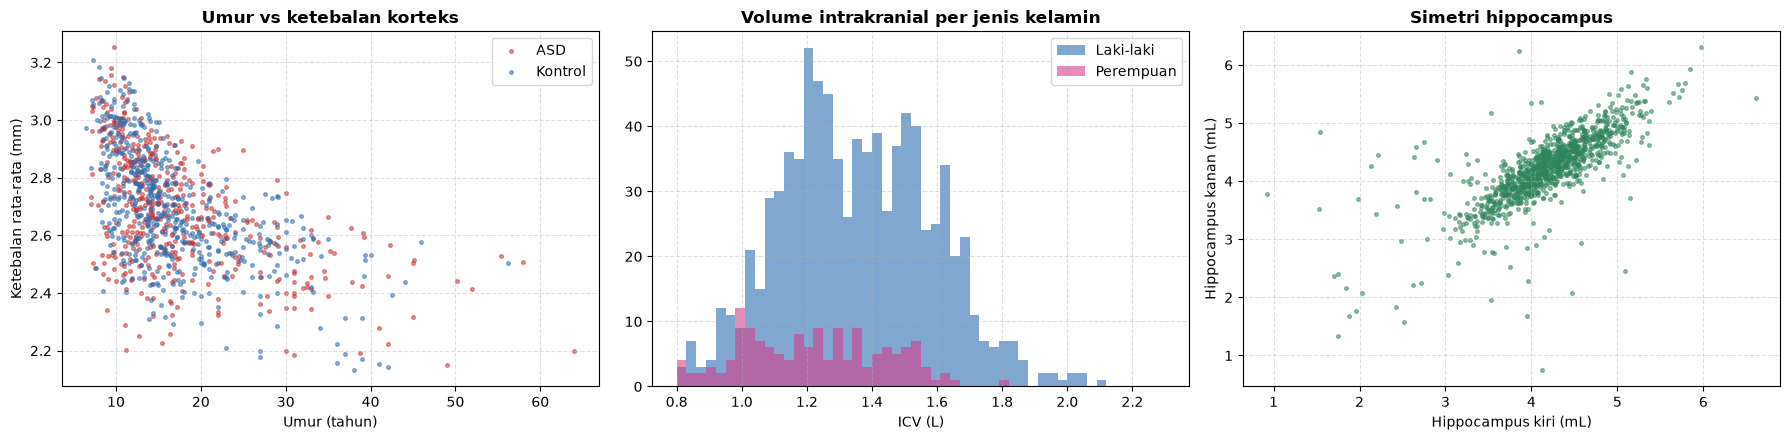

In [6]:
data = fitur.merge(subjek[["SUB_ID", "SITE_ID", "DX_GROUP", "AGE_AT_SCAN", "SEX"]], on="SUB_ID")
data["ct_rata2"] = (data["global_lh_MeanThickness"] + data["global_rh_MeanThickness"]) / 2

uji = pd.DataFrame({
    "Uji": ["Korelasi umur vs ketebalan korteks rata-rata", "Median ICV laki-laki (L)", "Median ICV perempuan (L)",
            "Korelasi hippocampus kiri vs kanan", "Korelasi ketebalan rata-rata kiri vs kanan"],
    "Hasil": [data[["AGE_AT_SCAN", "ct_rata2"]].corr().iloc[0, 1],
              data.loc[data["SEX"] == 1, "global_ICV_mm3"].median() / 1e6,
              data.loc[data["SEX"] == 2, "global_ICV_mm3"].median() / 1e6,
              data[["aseg_vol_Left-Hippocampus", "aseg_vol_Right-Hippocampus"]].corr().iloc[0, 1],
              data[["global_lh_MeanThickness", "global_rh_MeanThickness"]].corr().iloc[0, 1]],
})
uji["Hasil"] = uji["Hasil"].round(3)
display(uji)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for dx, w, n in [(1, "#C53030", "ASD"), (2, "#2B6CB0", "Kontrol")]:
    d = data[data["DX_GROUP"] == dx]
    axes[0].scatter(d["AGE_AT_SCAN"], d["ct_rata2"], s=7, alpha=0.5, color=w, label=n)
axes[0].set_xlabel("Umur (tahun)"); axes[0].set_ylabel("Ketebalan rata-rata (mm)")
axes[0].set_title("Umur vs ketebalan korteks", fontweight="bold"); axes[0].legend()
for sex, w, n in [(1, "#2B6CB0", "Laki-laki"), (2, "#D53F8C", "Perempuan")]:
    axes[1].hist(data.loc[data["SEX"] == sex, "global_ICV_mm3"] / 1e6, bins=50, alpha=0.6, color=w, label=n, range=(0.8, 2.3))
axes[1].set_xlabel("ICV (L)"); axes[1].set_title("Volume intrakranial per jenis kelamin", fontweight="bold"); axes[1].legend()
axes[2].scatter(data["aseg_vol_Left-Hippocampus"] / 1000, data["aseg_vol_Right-Hippocampus"] / 1000, s=7, alpha=0.5,
                color="#2F855A")
axes[2].set_xlabel("Hippocampus kiri (mL)"); axes[2].set_ylabel("Hippocampus kanan (mL)")
axes[2].set_title("Simetri hippocampus", fontweight="bold")
for a in axes:
    a.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "07b_5_kewajaran_biologis.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. QC Hasil FreeSurfer

Output FreeSurfer PCP **tidak dikurasi**, sehingga kegagalan segmentasi perlu dideteksi. Kriteria (otomatis, ditetapkan sebelum pemodelan):

| Kriteria | Aturan | Indikasi kegagalan |
| :--- | :--- | :--- |
| ICV ekstrem | $\lvert z_{\text{robust}}\rvert > 4$ (median & MAD) | Estimasi ICV/registrasi Talairach gagal |
| ICV < 1.2 × GM total | rasio tidak mungkin secara anatomi | ICV terlalu kecil |
| GM tidak konsisten | GM total ≠ GM korteks + GM subkortikal (selisih > 1 mL) | Komponen volume tidak sinkron |
| Wilayah hilang | ada wilayah Desikan yang kosong | Parselasi tidak lengkap |
| Ketebalan ekstrem | ketebalan rata-rata < 1.5 mm atau > 4 mm | Rekonstruksi permukaan gagal |

In [7]:
icv = data["global_ICV_mm3"]
z_icv = (icv - icv.median()) / (1.4826 * (icv - icv.median()).abs().median())
qc = data[["SUB_ID", "FILE_ID", "SITE_ID", "DX_GROUP"]].copy()
qc["icv_ekstrem"] = z_icv.abs() > 4
qc["icv_kurang_dari_1_2x_gm"] = icv / data["global_TotalGrayVol"] < 1.2
qc["gm_tidak_konsisten"] = (data["global_TotalGrayVol"] - data["global_CortexVol"] - data["global_SubCortGrayVol"]).abs() > 1000
kolom_wilayah = [c for c in data.columns if c.startswith(("ct_", "sa_", "gmv_"))]
qc["wilayah_hilang"] = data[kolom_wilayah].isna().any(axis=1)
qc["ketebalan_ekstrem"] = (data["ct_rata2"] < 1.5) | (data["ct_rata2"] > 4)
kriteria = ["icv_ekstrem", "icv_kurang_dari_1_2x_gm", "gm_tidak_konsisten", "wilayah_hilang", "ketebalan_ekstrem"]
qc["gagal_qc"] = qc[kriteria].any(axis=1)
qc.to_csv(TABEL_DIR / "07b_qc_freesurfer.csv", index=False)

display(pd.DataFrame({"Kriteria": kriteria + ["TOTAL gagal (≥ 1 kriteria)"],
                      "Jumlah subjek": [int(qc[k].sum()) for k in kriteria] + [int(qc["gagal_qc"].sum())]}))
display(qc[qc["gagal_qc"]].groupby("SITE_ID").size().sort_values(ascending=False).to_frame("Gagal QC")
        .style.set_caption("Subjek gagal QC per situs"))
p = stats.chi2_contingency(pd.crosstab(qc["gagal_qc"], qc["DX_GROUP"]))[1]
print(f"Proporsi ASD pada subjek gagal QC: {(qc.loc[qc['gagal_qc'], 'DX_GROUP'] == 1).mean() * 100:.1f}% "
      f"vs lolos QC: {(qc.loc[~qc['gagal_qc'], 'DX_GROUP'] == 1).mean() * 100:.1f}% (chi-square p = {p:.3f})")

,Kriteria,Jumlah subjek
0,icv_ekstrem,5
1,icv_kurang_dari_1_2x_gm,17
2,gm_tidak_konsisten,0
3,wilayah_hilang,8
4,ketebalan_ekstrem,0
5,TOTAL gagal (≥ 1 kriteria),22


,Gagal QC
SITE_ID,
UM_1,9
NYU,5
STANFORD,3
YALE,2
KKI,1
SDSU,1
UCLA_2,1


Proporsi ASD pada subjek gagal QC: 59.1% vs lolos QC: 48.6% (chi-square p = 0.447)


## 7. Gambaran Deskriptif: ASD vs Kontrol dan Efek Situs

Dua hal yang perlu diketahui sebelum pemodelan:
1. **Seberapa besar perbedaan ASD vs kontrol** pada fitur sMRI — diukur dengan *effect size* Cohen's $d$. Literatur ABIDE melaporkan perbedaan struktural yang kecil.
2. **Seberapa besar efek situs** — perbedaan scanner/protokol antar situs bisa jauh lebih besar dari perbedaan diagnosis, sehingga perlu normalisasi atau harmonisasi (misalnya ComBat) **di dalam setiap fold**.

> Analisis ini memakai seluruh subjek lolos QC dan bersifat **deskriptif**. Hasilnya **tidak boleh** dipakai untuk memilih fitur model (*data leakage*).

,Fitur,d (ASD − kontrol),|d|
9,ct_lh_lateraloccipital,0.165000,0.165000
43,ct_rh_lateraloccipital,0.165000,0.165000
4,ct_lh_entorhinal,-0.160000,0.160000
3,ct_lh_cuneus,0.138000,0.138000
19,ct_lh_pericalcarine,0.137000,0.137000
36,ct_rh_caudalmiddlefrontal,-0.129000,0.129000
38,ct_rh_entorhinal,-0.122000,0.122000
45,ct_rh_lingual,0.119000,0.119000
53,ct_rh_pericalcarine,0.115000,0.115000
50,ct_rh_parsopercularis,-0.111000,0.111000


Median |d| seluruh wilayah: 0.040 (efek kecil: |d| ≈ 0.2)


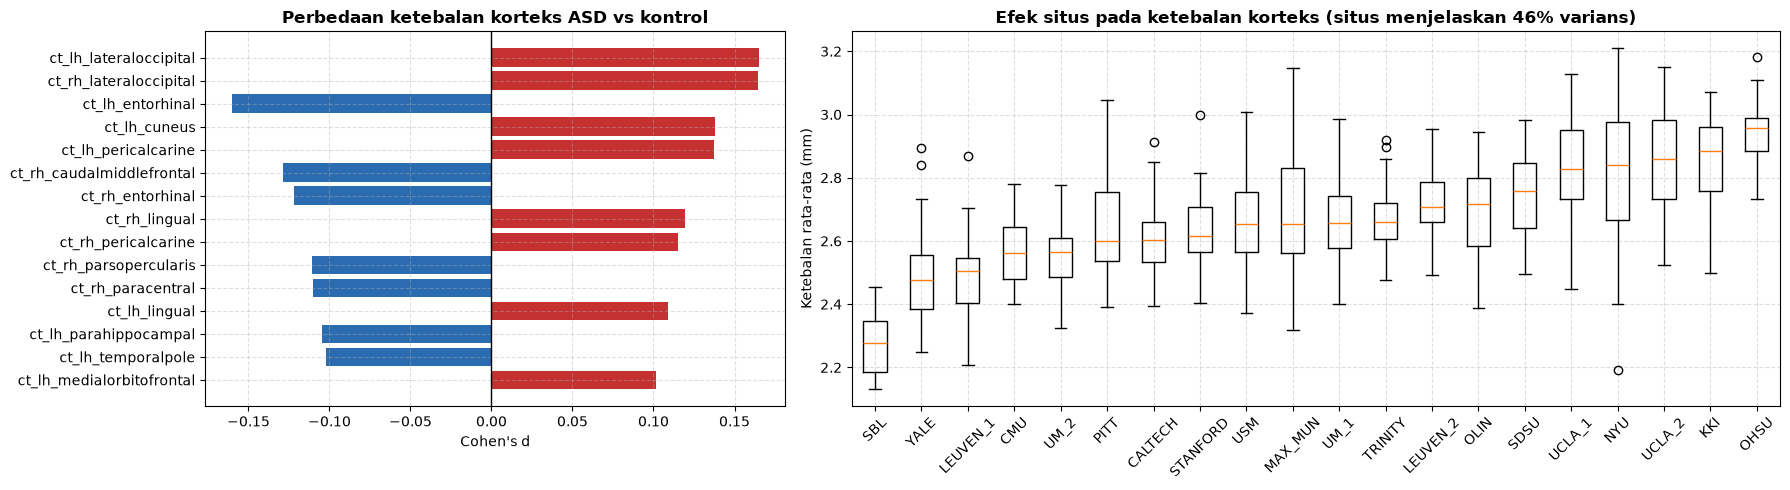

In [8]:
lolos = data[~qc["gagal_qc"].values]
def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

kolom_ct = [c for c in lolos.columns if c.startswith("ct_")]
efek = pd.DataFrame({"Fitur": kolom_ct,
                     "d (ASD − kontrol)": [cohen_d(lolos.loc[lolos["DX_GROUP"] == 1, c].dropna(),
                                                   lolos.loc[lolos["DX_GROUP"] == 2, c].dropna()) for c in kolom_ct]})
efek["|d|"] = efek["d (ASD − kontrol)"].abs()
efek = efek.sort_values("|d|", ascending=False)
display(efek.head(10).round(3).style.set_caption("10 wilayah dengan perbedaan ketebalan terbesar (deskriptif)"))
print(f"Median |d| seluruh wilayah: {efek['|d|'].median():.3f} (efek kecil: |d| ≈ 0.2)")

urut = lolos.groupby("SITE_ID")["ct_rata2"].median().sort_values().index
ss_total = ((lolos["ct_rata2"] - lolos["ct_rata2"].mean()) ** 2).sum()
ss_situs = sum(len(g) * (g.mean() - lolos["ct_rata2"].mean()) ** 2 for _, g in lolos.groupby("SITE_ID")["ct_rata2"])

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.6]})
top = efek.head(15)[::-1]
axes[0].barh(top["Fitur"], top["d (ASD − kontrol)"], color=np.where(top["d (ASD − kontrol)"] > 0, "#C53030", "#2B6CB0"))
axes[0].axvline(0, color="black", lw=1); axes[0].set_xlabel("Cohen's d")
axes[0].set_title("Perbedaan ketebalan korteks ASD vs kontrol", fontweight="bold")
axes[1].boxplot([lolos.loc[lolos["SITE_ID"] == s, "ct_rata2"] for s in urut], tick_labels=urut)
axes[1].tick_params(axis="x", rotation=45); axes[1].set_ylabel("Ketebalan rata-rata (mm)")
axes[1].set_title(f"Efek situs pada ketebalan korteks (situs menjelaskan {ss_situs / ss_total * 100:.0f}% varians)",
                  fontweight="bold")
for a in axes:
    a.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "07b_7_efek_diagnosis_dan_situs.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Ringkasan

In [9]:
display(pd.DataFrame({
    "Ukuran": ["Subjek rilis PCP", "Statistik FreeSurfer tersedia", "Lolos QC", "Jumlah fitur per subjek",
               "Berkas fitur", "Berkas QC"],
    "Nilai": [len(subjek), len(fitur), int((~qc["gagal_qc"]).sum()), fitur.shape[1] - 2,
              str(OUT_CSV.relative_to(ROOT)), "result/tabel/07b_qc_freesurfer.csv"],
}))

,Ukuran,Nilai
0,Subjek rilis PCP,1035
1,Statistik FreeSurfer tersedia,1035
2,Lolos QC,1013
3,Jumlah fitur per subjek,265
4,Berkas fitur,data\processed\smri_features\smri_freesurfer_f...
5,Berkas QC,result/tabel/07b_qc_freesurfer.csv


### Kesimpulan

1. Statistik FreeSurfer PCP berhasil diubah menjadi **satu tabel fitur** per subjek: ukuran global, volume struktur aseg, serta **ketebalan, luas permukaan, dan volume GM** untuk 68 wilayah Desikan-Killiany.
2. Identitas berkas diverifikasi dan fitur **wajar secara biologis**.
3. Subjek yang gagal QC dicatat di `07b_qc_freesurfer.csv` dan dikeluarkan pada penetapan kohort (notebook 08).
4. Perbedaan ASD vs kontrol pada ketebalan korteks **kecil**, sedangkan **efek situs** cukup besar → normalisasi/harmonisasi fitur sMRI harus dilakukan **di dalam setiap fold** saat pemodelan.